<a href="https://colab.research.google.com/github/parvezsardar13/Yulu_Buisness_case/blob/main/Yulu_Buisness_case.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yulu: What Drives Demand for Shared Electric Cycles?
**Problem statement.** Yulu's revenue has dipped. Using hourly rental data (Jan 2011 – Dec 2012), we identify which variables significantly affect demand (`count`) and how well they explain it, using hypothesis tests and a regression.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings; warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('bike_sharing.csv',parse_dates=['datetime'])
df.shape

(10886, 12)

In [ ]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


## 1. Exploratory Data Analysis

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(8)
memory usage: 1020.7 KB


In [ ]:
display(df.describe().T)


,count,mean,min,25%,50%,75%,max,std
datetime,10886,2011-12-27 05:56:22.399411968,2011-01-01 00:00:00,2011-07-02 07:15:00,2012-01-01 20:30:00,2012-07-01 12:45:00,2012-12-19 23:00:00,NaN
season,10886.0,2.506614,1.0,2.0,3.0,4.0,4.0,1.116174
holiday,10886.0,0.028569,0.0,0.0,0.0,0.0,1.0,0.166599
workingday,10886.0,0.680875,0.0,0.0,1.0,1.0,1.0,0.466159
weather,10886.0,1.418427,1.0,1.0,1.0,2.0,4.0,0.633839
temp,10886.0,20.23086,0.82,13.94,20.5,26.24,41.0,7.79159
atemp,10886.0,23.655084,0.76,16.665,24.24,31.06,45.455,8.474601
humidity,10886.0,61.88646,0.0,47.0,62.0,77.0,100.0,19.245033
windspeed,10886.0,12.799395,0.0,7.0015,12.998,16.9979,56.9969,8.164537
casual,10886.0,36.021955,0.0,4.0,17.0,49.0,367.0,49.960477


In [ ]:
print('Missing:',df.isna().sum().sum(),'| Duplicates:',df.duplicated().sum())
print(df.datetime.min(),'to',df.datetime.max())

Missing: 0 | Duplicates: 0
2011-01-01 00:00:00 to 2012-12-19 23:00:00


**Findings:** 10,886 hourly rows, 12 columns, no missing values, no duplicates. Data covers 2011-01-01 to 2012-12-19 (the last ~12 days of each month are not in the file, as is typical of this dataset), so no imputation is needed.

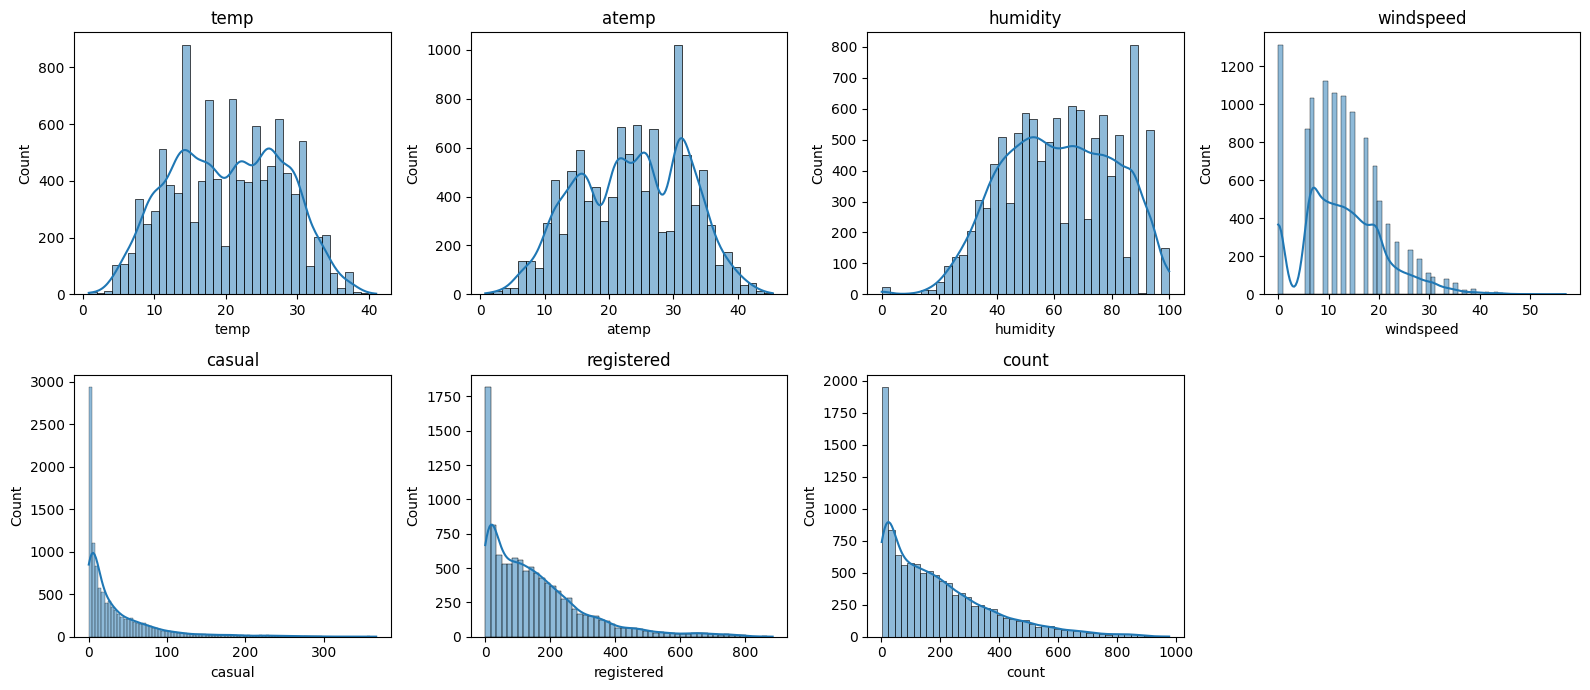

temp          0.00
atemp        -0.10
humidity     -0.09
windspeed     0.59
casual        2.50
registered    1.52
count         1.24
dtype: float64


In [ ]:
df['season']=df.season.map({1:'spring',2:'summer',3:'fall',4:'winter'})
df['weather_c']=df.weather
num=['temp','atemp','humidity','windspeed','casual','registered','count']
fig,ax=plt.subplots(2,4,figsize=(16,7))
for a,c in zip(ax.flat,num):
  sns.histplot(df[c],kde=True,ax=a)
  a.set_title(c)
ax.flat[-1].axis('off')
plt.tight_layout()
plt.show()
print(df[num].skew().round(2))

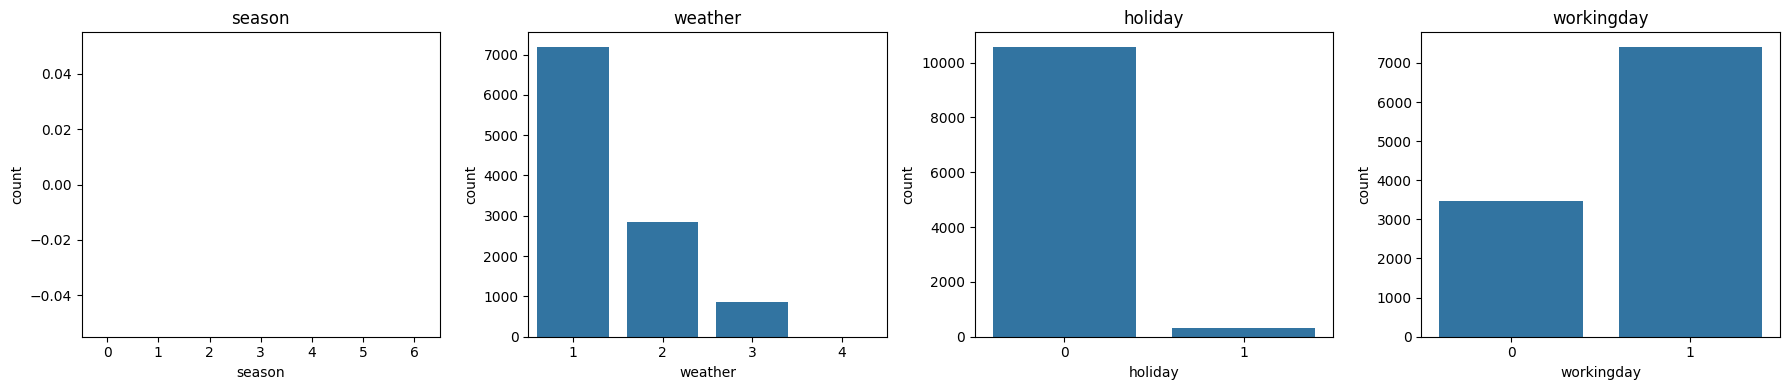

weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


In [ ]:
fig,ax=plt.subplots(1,4,figsize=(18,4))
for a,c in zip(ax,['season','weather','holiday','workingday']):
    sns.countplot(x=c,data=df,ax=a)
    a.set_title(c)
plt.tight_layout()
plt.show()
print(df.weather.value_counts())

**Findings:** `count`, `casual`, `registered` are right-skewed (count skew ≈ 1.24). Seasons are balanced. Weather is dominated by clear (66%) and mist (26%); only **1 row** has weather = 4 (heavy rain). Only ~3% of hours are holidays; ~68% are working days.

### Outliers

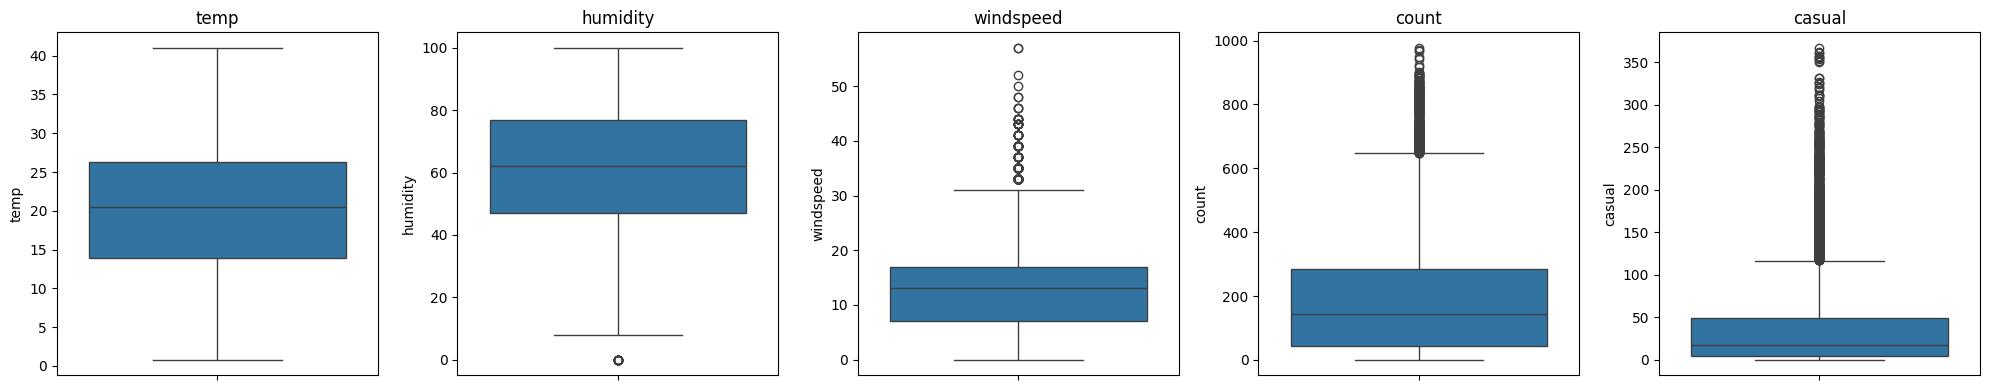

humidity IQR outliers: 22
windspeed IQR outliers: 227
count IQR outliers: 300
windspeed==0 rows: 1313 | humidity==0 rows: 22


In [ ]:
fig,ax=plt.subplots(1,5,figsize=(20,4))
vari=['temp','humidity','windspeed','count','casual']
for a,c in zip(ax,vari):
  sns.boxplot(y=df[c],ax=a)
  a.set_title(c)
plt.tight_layout()
plt.show()
for c in ['humidity','windspeed','count']:
    q1,q3=df[c].quantile([.25,.75])
    i=q3-q1
    print(c,'IQR outliers:',((df[c]<q1-1.5*i)|(df[c]>q3+1.5*i)).sum())
print('windspeed==0 rows:',(df.windspeed==0).sum(),'| humidity==0 rows:',(df.humidity==0).sum())

**Findings:** `count` has 300 IQR outliers (~2.8%), `windspeed` 227, `humidity` 22. The high `count` values are genuine rush-hour peaks (up to 977), not errors, so I **retain them** for the hypothesis tests (clipping would distort real demand). Since the tests used are robust at this sample size, and I cross-check with non-parametric tests, this is safe. Note 1,313 rows have windspeed = 0, which likely means "not recorded" rather than true calm.

## 2. Relationships between variables

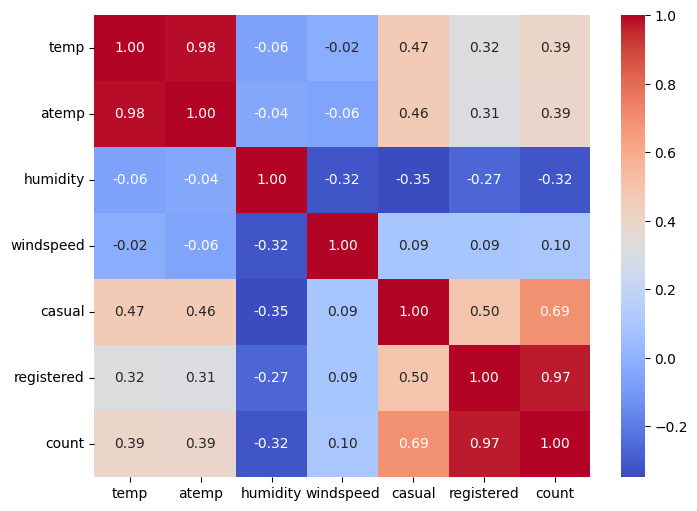

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df[num].corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.show()

**Findings:** `temp` and `atemp` correlate at **0.98**, so they carry the same information (keep one, `temp`, in models to avoid multicollinearity). `casual` and `registered` sum to `count` (r with count: 0.69 and 0.97), so they are components of the target, not predictors. Demand rises with temperature (r = 0.39) and falls with humidity (r = −0.32); windspeed is weakly related (0.10).

## 3. Working day vs. non-working day: 2-sample t-test

**H0:** mean hourly rentals are equal on working and non-working days. **H1:** they differ. α = 0.05.

In [ ]:
wd=df[df.workingday==1]['count']; we=df[df.workingday==0]['count']
print('means:',wd.mean().round(1),we.mean().round(1))
print('Levene:',stats.levene(wd,we))
print('2 t test :',stats.ttest_ind(wd,we))
print('Welch t:',stats.ttest_ind(wd,we,equal_var=False))
print('Mann-Whitney:',stats.mannwhitneyu(wd,we))
print(df.groupby('workingday')[['casual','registered']].mean().round(1))

means: 193.0 188.5
Levene: LeveneResult(statistic=np.float64(0.004972848886504472), pvalue=np.float64(0.9437823280916695))
2 t test : TtestResult(statistic=np.float64(1.2096277376026694), pvalue=np.float64(0.22644804226361348), df=np.float64(10884.0))
Welch t: TtestResult(statistic=np.float64(1.2362580418223226), pvalue=np.float64(0.21640312280695098), df=np.float64(7176.288413844308))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(12868495.5), pvalue=np.float64(0.9679139953914079))
            casual  registered
workingday                    
0             59.3       129.2
1             25.1       167.9


**Result:** mean demand is 193.0 (working) vs 188.5 (non-working); t = 1.21, **p = 0.226 > 0.05** (Welch p = 0.216, Mann-Whitney p = 0.97). **We fail to reject H0**: no significant difference in *total* hourly rentals.
**Nuance:** the mix differs. Casual users average 59 on non-working days vs 25 on working days, while registered users average 168 vs 129 the other way, so the two effects cancel in the total.

## 4. Weather vs. demand: one-way ANOVA

**H0:** mean demand is equal across weather types. **H1:** at least one differs. α = 0.05. Weather 4 has a single observation, so it is **excluded** from the test (no variance estimate possible) and reported separately.

         count   mean    std  median
weather                             
1         7192  205.2  188.0   161.0
2         2834  179.0  168.4   134.0
3          859  118.8  138.6    71.0


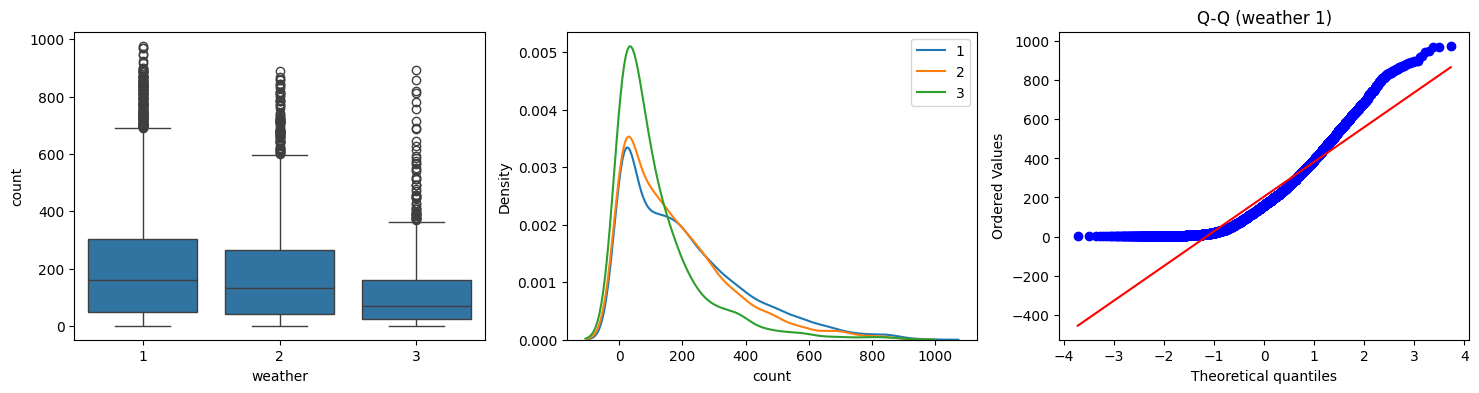

1 skew 1.14 kurt 0.96 Shapiro p 1.194149907502766e-50
2 skew 1.29 kurt 1.58 Shapiro p 9.77783910611011e-43
3 skew 2.18 kurt 5.96 Shapiro p 3.875893017395983e-33
Levene LeveneResult(statistic=np.float64(81.67574924435011), pvalue=np.float64(6.198278710731511e-36))
ANOVA F_onewayResult(statistic=np.float64(98.28356881946705), pvalue=np.float64(4.976448509904196e-43))
Kruskal KruskalResult(statistic=np.float64(204.95566833068537), pvalue=np.float64(3.122066178659941e-45))
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     1      2 -26.2813   0.0  -35.6159 -16.9466   True
     1      3 -86.3905   0.0 -101.5841 -71.1968   True
     2      3 -60.1092   0.0   -76.502 -43.7165   True
------------------------------------------------------


In [ ]:
d=df[df.weather!=4]
print(d.groupby('weather')['count'].agg(['count','mean','std','median']).round(1))
fig,ax=plt.subplots(1,3,figsize=(18,4))
sns.boxplot(x='weather',y='count',data=d,ax=ax[0])
for w in [1,2,3]:
  sns.kdeplot(d[d.weather==w]['count'],ax=ax[1],label=w)
ax[1].legend()
stats.probplot(d[d.weather==1]['count'],plot=ax[2])
ax[2].set_title('Q-Q (weather 1)')
plt.show()
g=[d[d.weather==w]['count'] for w in [1,2,3]]
for w,x in zip([1,2,3],g):
  print(w,'skew',round(stats.skew(x),2),'kurt',round(stats.kurtosis(x),2),'Shapiro p',stats.shapiro(x.sample(min(len(x),5000),random_state=1)).pvalue)
print('Levene',stats.levene(*g))
print('ANOVA',stats.f_oneway(*g))
print('Kruskal',stats.kruskal(*g))
print(pairwise_tukeyhsd(d['count'],d.weather))

**Assumptions:** Shapiro-Wilk rejects normality in every group (p ≈ 0) and Levene rejects equal variances (p ≈ 3.5e-35); the histograms and Q-Q plots confirm right skew. As instructed, we continue, but double-check with the non-parametric Kruskal-Wallis test.
**Result:** ANOVA F = 65.5, **p = 5.5e-42**; Kruskal-Wallis H = 205, p = 3.5e-44. **Reject H0**: demand differs by weather. Tukey: all pairs differ. Mean hourly rentals: clear 205 > mist 179 > light rain/snow 119 (about 42% lower than clear).

## 5. Season vs. demand: one-way ANOVA

**H0:** mean demand is equal across the four seasons. **H1:** at least one differs. α = 0.05.

In [ ]:
print(df.groupby('season')['count'].agg(['count','mean','std','median']).round(1))

        count   mean    std  median
season                             
1        2686  116.3  125.3    78.0
2        2733  215.3  192.0   172.0
3        2733  234.4  197.2   195.0
4        2734  199.0  177.6   161.0


        count   mean    std  median
season                             
fall     2733  234.4  197.2   195.0
spring   2686  116.3  125.3    78.0
summer   2733  215.3  192.0   172.0
winter   2734  199.0  177.6   161.0


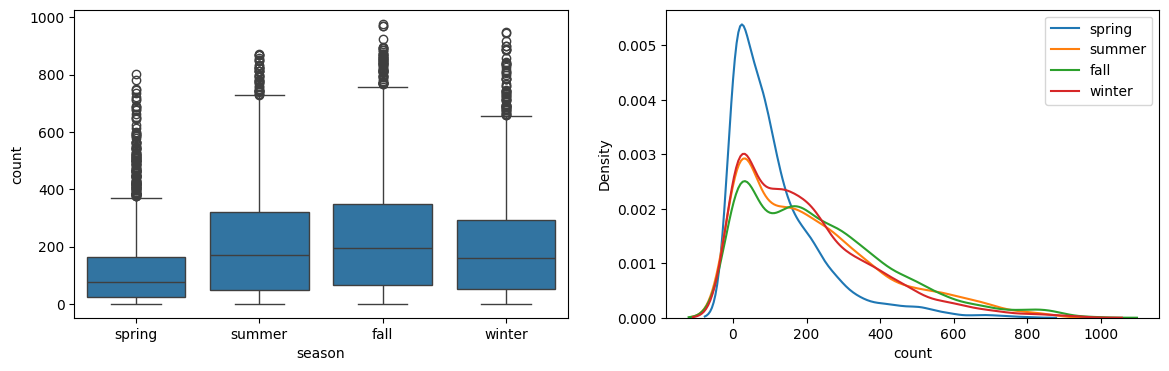

spring skew 1.89 Shapiro p 8.749584618867662e-49
summer skew 1.0 Shapiro p 6.039374406270491e-39
fall skew 0.99 Shapiro p 1.043680518918597e-36
winter skew 1.17 Shapiro p 1.1299244409282836e-39
Levene LeveneResult(statistic=np.float64(187.7706624026276), pvalue=np.float64(1.0147116860043298e-118))
ANOVA F_onewayResult(statistic=np.float64(236.94671081032098), pvalue=np.float64(6.164843386499654e-149))
Kruskal KruskalResult(statistic=np.float64(699.6668548181988), pvalue=np.float64(2.479008372608633e-151))
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
  fall spring -118.0739    0.0 -130.3276 -105.8202   True
  fall summer  -19.1658 0.0003  -31.3662   -6.9653   True
  fall winter  -35.4288    0.0  -47.6282  -23.2295   True
spring summer   98.9081    0.0   86.6544  111.1618   True
spring winter    82.645    0.0   70.3924   94.8976   True
summer winter  -16.2631 0

In [ ]:
print(df.groupby('season')['count'].agg(['count','mean','std','median']).round(1))
fig,ax=plt.subplots(1,2,figsize=(14,4))
sns.boxplot(x='season',y='count',data=df,order=['spring','summer','fall','winter'],ax=ax[0])
for s in ['spring','summer','fall','winter']: sns.kdeplot(df[df.season==s]['count'],ax=ax[1],label=s)
ax[1].legend()
plt.show()
g=[df[df.season==s]['count'] for s in ['spring','summer','fall','winter']]
for s,x in zip(['spring','summer','fall','winter'],g):
  print(s,'skew',round(stats.skew(x),2),'Shapiro p',stats.shapiro(x).pvalue)
print('Levene',stats.levene(*g))
print('ANOVA',stats.f_oneway(*g))
print('Kruskal',stats.kruskal(*g))
print(pairwise_tukeyhsd(df['count'],df.season))

**Assumptions:** normality and equal variance both fail (all Shapiro p ≈ 0; Levene p ≈ 1e-118); distributions are right-skewed. Kruskal-Wallis is used as a check.
**Result:** ANOVA F = 236.9, **p ≈ 6e-149**; Kruskal H = 699.7, p ≈ 2e-151. **Reject H0**: demand differs by season. Mean hourly rentals: fall 234 > summer 215 > winter 199 > spring 116. All pairs differ (Tukey).
**Caveat on labels:** the data dictionary says 1 = spring, but spring having the *lowest* demand (and the data starting 1 Jan in season 1) suggests the codes may be offset by one season (season 1 ≈ winter Jan-Mar). Worth confirming with the data owner before making season-specific calls. Yulu's real Indian seasons also differ (monsoon, summer heat).

## 6. Weather vs. season: chi-square test of independence

**H0:** weather and season are independent. **H1:** they are associated. α = 0.05.

In [ ]:
ct=pd.crosstab(df.season,df.weather)
display(ct)
chi2,p,dof,exp=stats.chi2_contingency(ct)
print(chi2,p,dof)
display(pd.DataFrame(exp,index=ct.index,columns=ct.columns).round(1))
ct3=ct[[1,2,3]]
chi2b,pb,dofb,expb=stats.chi2_contingency(ct3)
print('Excluding weather 4:',chi2b,pb,dofb,'min expected',expb.min().round(1))

weather,1,2,3,4
season,,,,
fall,1930,604,199,0
spring,1759,715,211,1
summer,1801,708,224,0
winter,1702,807,225,0


49.15865559689363 1.5499250736864862e-07 9


weather,1,2,3,4
season,,,,
fall,1805.6,711.5,215.7,0.3
spring,1774.5,699.3,211.9,0.2
summer,1805.6,711.5,215.7,0.3
winter,1806.3,711.8,215.7,0.3


Excluding weather 4: 46.10145731073249 2.8260014509929343e-08 6 min expected 211.9


**Result:** with all four weather levels, χ² = 49.2, dof = 9, p = 1.5e-7, but the weather-4 column has expected counts < 5, violating the test's validity. The code re-runs the test **excluding weather 4**, which is the valid version: χ² = 46.1, dof = 6, **p = 2.8e-8**, all expected counts > 200. In both cases p < 0.05, so we **reject H0**: weather conditions are associated with season (e.g., fall has the most clear hours, winter the most misty ones). The association is statistically significant but modest in size.

## Insights & Recommendations
1. **Weather matters a lot.** Light rain/snow cuts demand ~42% vs clear skies. Use weather forecasts to plan rebalancing, dynamic pricing, and rain-day promotions.
2. **Seasonality is strong.** Fall and summer are peaks; spring (as coded) is far lower. Align fleet size and maintenance windows with low-demand periods, after verifying the season coding.
3. **Total demand is the same on working and non-working days**, but the *customer mix* flips: commuters (registered) on workdays, leisure riders (casual) on weekends. Run commuter plans/passes on weekdays and weekend leisure offers separately.
4. **Temperature and humidity are the key continuous drivers.** Expect more demand on warm, dry days; for India, check whether extreme heat reverses the effect (this US-style data tops out at 41°C).
5. **Time of day explains more than any weather variable.** Position bikes near offices/transit before 8am and 5pm.
6. **Caveats:** this dataset is a US-style bike-sharing dataset applied to Yulu's case, data is non-normal (non-parametric checks agree), weather 4 has one observation, and regressions show association, not causation. Validate with real Indian Yulu data before acting.